# Prediksi Minat Beli Pengunjung Toko Online
## File Utama
**Tujuan:** memprediksi apakah pengunjung toko online akan **membeli** (`Revenue` = True/False) dari data perilaku browsing, lalu mengelompokkan pengunjung ke segmen.

**Output akhir:**
1. Tabel perbandingan algoritma + model terbaik (`model_prediksi_belanja.joblib`)
2. Fitur yang paling berpengaruh terhadap pembelian
3. Segmen pengunjung (K-Means) + rekomendasi bisnis
4. Aplikasi prediksi sederhana (`app.py`) lewat localhost

**Pembagian tugas file:**
| File | Tugas |
|---|---|
| `utama.ipynb` (ini) | Penjelasan, EDA, cleaning, split, **evaluasi & perbandingan**, interpretasi, simpan model |
| `algoritma/*.py` | **Hanya mencoba (melatih) 1 algoritma per file**: rf, xgb, svm, knn, ann, kmeans |
| `app.py` | Aplikasi Streamlit |


## 1. Penjelasan Dataset
**Online Shoppers Purchasing Intention** (12.330 sesi kunjungan, 1 baris = 1 sesi). Target: `Revenue`.

| Kelompok | Kolom | Arti |
|---|---|---|
| Halaman dikunjungi | `Administrative`, `Informational`, `ProductRelated` | Jumlah halaman per jenis (akun, informasi, produk) |
| Durasi | `*_Duration` | Lama (detik) di tiap jenis halaman |
| Metrik Google Analytics | `BounceRates`, `ExitRates`, `PageValues` | Rasio keluar tanpa aksi, rasio keluar, nilai halaman sebelum transaksi |
| Waktu | `SpecialDay`, `Month`, `Weekend` | Kedekatan hari spesial, bulan, akhir pekan |
| Teknis & pengunjung | `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType` | Kode perangkat/wilayah/sumber trafik, tipe pengunjung |
| **Target** | `Revenue` | Apakah sesi berakhir pembelian |

**Jenis masalah:** klasifikasi biner (supervised) dengan kelas tidak seimbang (pembeli ±15%).

## Setup


In [1]:
# %pip install numpy pandas scikit-learn matplotlib seaborn xgboost joblib streamlit
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

DATA_PATH = 'datasetshope/online_shoppers_intention.csv' 
SEED = 42
sns.set_style('whitegrid')

## 2. Load Data

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. EDA
Mengenali tipe data, missing, duplikat, distribusi target, dan pengaruh fitur terhadap pembelian.

In [3]:
df.info()
print('\nMissing:', df.isna().sum().sum(), '| Duplikat:', df.duplicated().sum())
print(df['Revenue'].value_counts(normalize=True).round(3))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


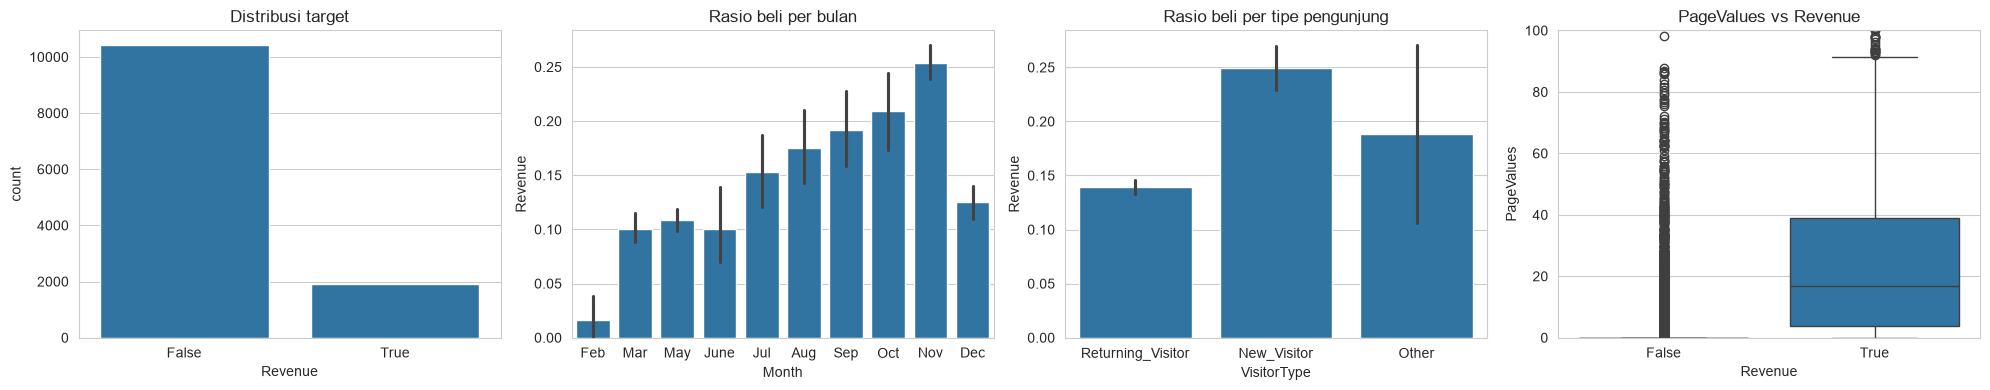

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
sns.countplot(x='Revenue', data=df, ax=ax[0]); ax[0].set_title('Distribusi target')
sns.barplot(x='Month', y='Revenue', data=df, ax=ax[1], order=['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']); ax[1].set_title('Rasio beli per bulan')
sns.barplot(x='VisitorType', y='Revenue', data=df, ax=ax[2]); ax[2].set_title('Rasio beli per tipe pengunjung')
sns.boxplot(x='Revenue', y='PageValues', data=df, ax=ax[3]); ax[3].set_ylim(0, 100); ax[3].set_title('PageValues vs Revenue')
plt.tight_layout(); plt.show()

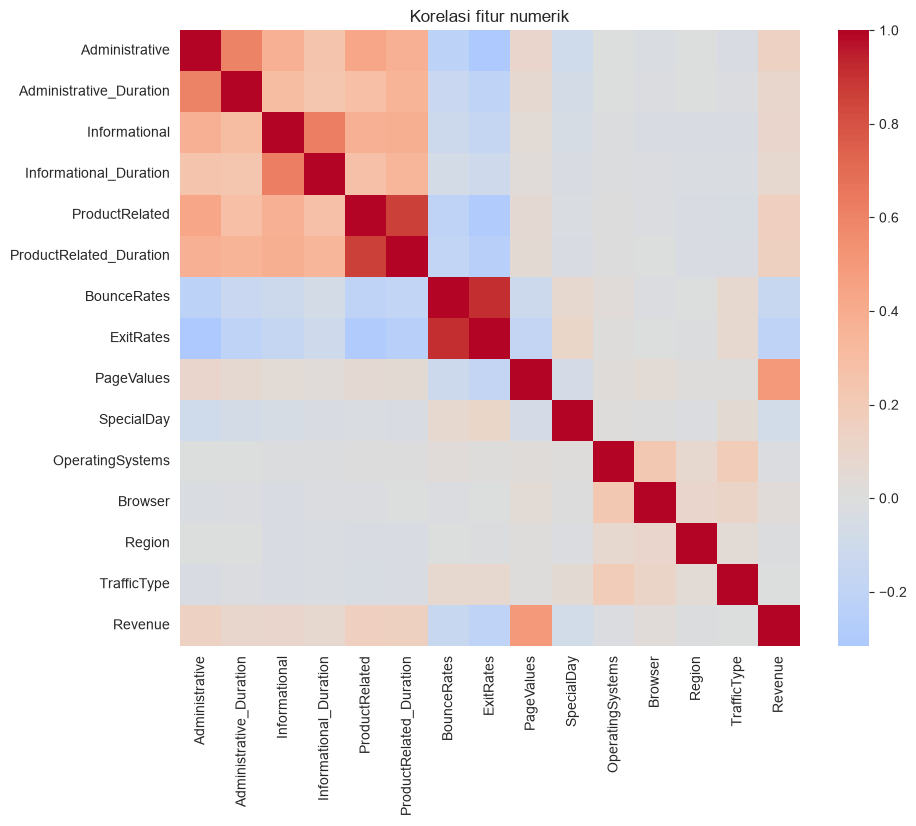

In [5]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes('number').assign(Revenue=df['Revenue'].astype(int)).corr(), cmap='coolwarm', center=0)
plt.title('Korelasi fitur numerik'); plt.show()

## 4. Data Cleaning
Hapus duplikat dan ubah tipe data. Kolom kode (`OperatingSystems`, `Browser`, `Region`, `TrafficType`) adalah **kategori**, bukan angka berurutan.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
df['Revenue'] = df['Revenue'].astype(int)
df['Weekend'] = df['Weekend'].astype(int)

cat_cols = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
df[cat_cols] = df[cat_cols].astype(str)
num_cols = [c for c in df.columns if c not in cat_cols + ['Revenue']]

print('Ukuran setelah cleaning:', df.shape)

Ukuran setelah cleaning: (12205, 18)


## 5. Split & Persiapan untuk Uji Algoritma
Split 80/20 dengan `stratify` (proporsi pembeli tetap sama). Preprocessing `prep` (scaling + One-Hot) dibuat sekali di sini lalu **dipakai semua algoritma**, supaya perbandingannya adil.

In [7]:
X = df[num_cols + cat_cols]
y = df['Revenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

prep = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Rasio beli train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (9764, 17) | Test: (2441, 17)
Rasio beli train/test: 0.156 0.156


## 6. Uji Algoritma (memanggil file `algoritma/`)
Setiap algoritma punya file nya sendiri dan di file utama ini, file file algoritma itu dipanggil dengan tujuan biar ga berantakan di file utama nya dan lebih rapih. masing masing algoritma menerima data yang udah siap ('prep'. 'x_train'. 'y_train') dan balikin model model yang udah dilatih 

- Tambah algoritma: buat file baru di `algoritma/` (contoh: `knn.py`), lalu masukkan ke daftar `daftar`
- Hanya cek satu algoritma: `nama, model = knn.latih(prep, X_train, y_train)`

In [8]:
from algoritma import rf, xgb, svm, knn, ann      # <- memanggil file tiap algoritma

daftar = [rf, xgb, svm, knn, ann]
model_jadi = {}
for algo in daftar:
    nama, model = algo.latih(prep, X_train, y_train)
    model_jadi[nama] = model
    print('selesai dilatih:', nama)

Parameter terbaik RF: {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 20}
selesai dilatih: Random Forest (tuned)
selesai dilatih: XGBoost
selesai dilatih: SVM
selesai dilatih: KNN
selesai dilatih: ANN (MLP)


## 7. Evaluasi & Perbandingan
Semua model dinilai pada **data uji yang sama**. Pakai Precision, Recall, **F1**, ROC-AUC, PR-AUC (bukan akurasi, karena kelas tidak seimbang).

In [9]:
def nilai(model):
    pred = model.predict(X_test)
    skor = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    return {'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'ROC-AUC': roc_auc_score(y_test, skor),
            'PR-AUC': average_precision_score(y_test, skor)}

hasil = pd.DataFrame({n: nilai(m) for n, m in model_jadi.items()}).T.sort_values('F1', ascending=False).round(3)
hasil.to_csv('hasil_perbandingan.csv')
hasil

,Precision,Recall,F1,ROC-AUC,PR-AUC
Random Forest (tuned),0.624,0.751,0.682,0.924,0.714
XGBoost,0.556,0.846,0.671,0.936,0.754
SVM,0.561,0.775,0.651,0.908,0.664
ANN (MLP),0.694,0.581,0.632,0.922,0.711
KNN,0.667,0.398,0.498,0.798,0.491


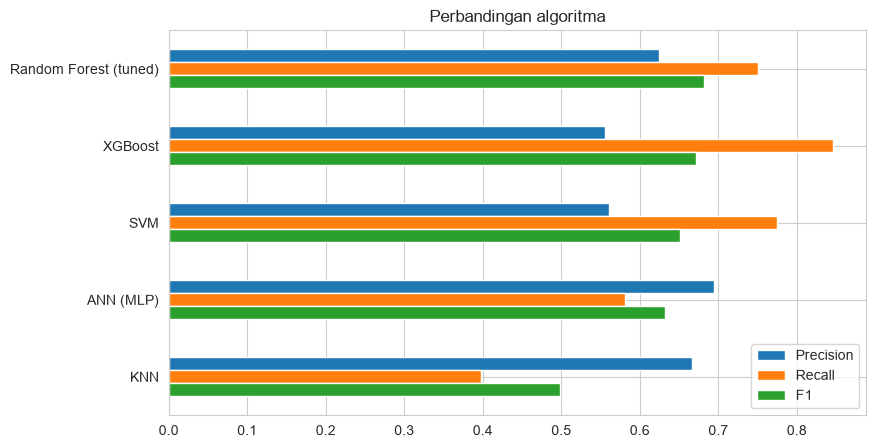

Model terbaik (F1 tertinggi): Random Forest (tuned)


In [10]:
hasil[['Precision', 'Recall', 'F1']].plot(kind='barh', figsize=(9, 5)).invert_yaxis()
plt.title('Perbandingan algoritma'); plt.show()

best_name = hasil.index[0]
best_model = model_jadi[best_name]
print('Model terbaik (F1 tertinggi):', best_name)

## 8. Evaluasi Model Terbaik
Confusion matrix, kurva ROC, dan Precision-Recall.

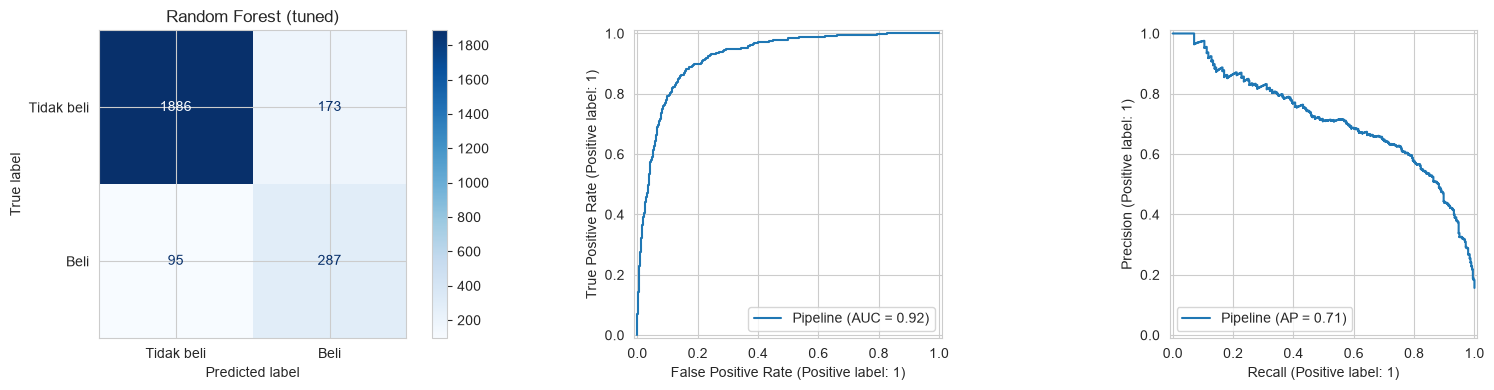

              precision    recall  f1-score   support

  Tidak beli       0.95      0.92      0.93      2059
        Beli       0.62      0.75      0.68       382

    accuracy                           0.89      2441
   macro avg       0.79      0.83      0.81      2441
weighted avg       0.90      0.89      0.89      2441



In [11]:
pred = best_model.predict(X_test)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Tidak beli', 'Beli'], cmap='Blues', ax=ax[0])
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=ax[1])
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=ax[2])
ax[0].set_title(best_name); plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, target_names=['Tidak beli', 'Beli']))

## 9. Interpretasi
Fitur yang paling menentukan pembelian (*permutation importance*: seberapa turun F1 saat fitur diacak).

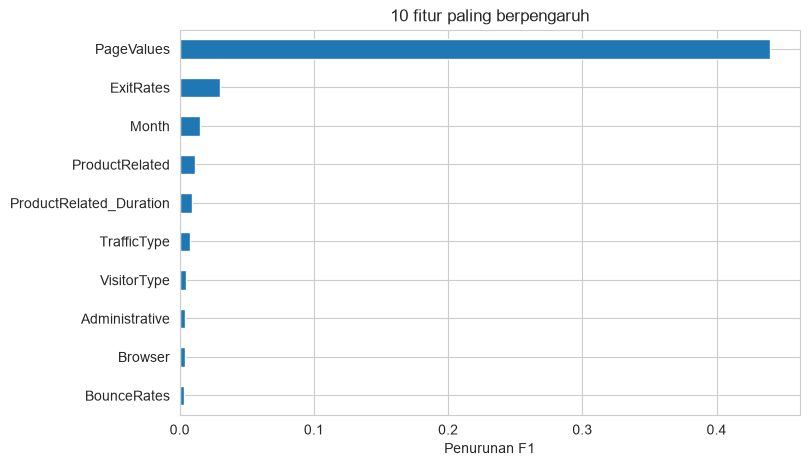

In [12]:
perm = permutation_importance(best_model, X_test, y_test, scoring='f1', n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('10 fitur paling berpengaruh'); plt.xlabel('Penurunan F1'); plt.show()

## 10. Segmentasi Pengunjung (K-Means)
Algoritma unsupervised, dipanggil dari `algoritma/kmeans.py`. Jumlah cluster dipilih dengan silhouette score.

{2: 0.476, 3: 0.505, 4: 0.402, 5: 0.414, 6: 0.412, 7: 0.377}


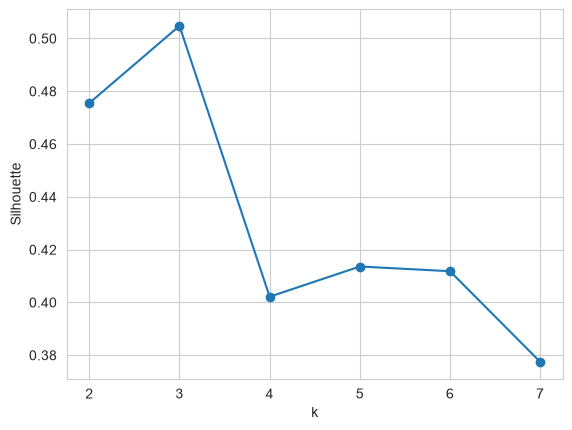

In [13]:
from algoritma import kmeans                      

sil = kmeans.cari_k(df)
print({k: round(v, 3) for k, v in sil.items()})
plt.plot(list(sil), list(sil.values()), marker='o'); plt.xlabel('k'); plt.ylabel('Silhouette'); plt.show()

In [14]:
K = max(sil, key=sil.get)          # boleh diganti manual
df, profil = kmeans.segmentasi(df, K)
profil

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,Rasio_Beli,Jumlah
Cluster,,,,,,,,,,,
0,0.05,1.62,0.02,0.10,3.23,63.40,0.16,0.18,0.00,0.01,921
1,1.71,51.24,0.22,8.24,23.88,874.11,0.01,0.03,5.89,0.15,9662
2,7.38,308.21,2.52,212.90,97.05,3839.22,0.01,0.02,9.68,0.28,1622


**Rekomendasi bisnis (isi sendiri):** beri nama tiap cluster dan tentukan strateginya, mis. promo untuk cluster dengan durasi tinggi tapi rasio beli rendah.

## 11. Simpan Model
Model yang paling bagus disimpan untuk dipake di app.py.

In [15]:
defaults = {c: float(X_train[c].median()) for c in num_cols}
defaults.update({c: X_train[c].mode()[0] for c in cat_cols})

joblib.dump({'model': best_model, 'name': best_name, 'features': list(X_train.columns),
             'defaults': defaults, 'months': sorted(df['Month'].unique()),
             'visitor_types': sorted(df['VisitorType'].unique())},
            'model_prediksi_belanja.joblib')
print('Tersimpan: model_prediksi_belanja.joblib ->', best_name)

Tersimpan: model_prediksi_belanja.joblib -> Random Forest (tuned)


## 12. Aplikasi
`app.py` ada di folder untuk mencoba pake model yang udah dilatih. Run di terminal: `streamlit run app.py`

## 13. Kesimpulan
- **Model terbaik:** Random Forest (tuned) dengan F1 = 0,68 dan Recall = 0,73 pada kelas pembeli. Model ini mengungguli XGBoost, SVM, ANN (MLP), dan KNN.
- **Fitur paling berpengaruh:** `PageValues` jauh paling dominan, disusul `ExitRates` dan `Month`. Pengunjung yang melihat halaman bernilai tinggi jauh lebih mungkin membeli.
- **Segmen pengunjung:** K-Means membentuk 3 segmen (k=3, silhouette tertinggi):
  1. *Pengunjung sekilas* (±900 sesi): hampir tidak berinteraksi, bounce dan exit rate tinggi, rasio beli ±1%.
  2. *Pengunjung umum* (±9.700 sesi): interaksi sedang, rasio beli ±15%.
  3. *Penjelajah aktif* (±1.600 sesi): banyak halaman dan durasi panjang, rasio beli tertinggi ±28%.
- **Rekomendasi bisnis:** Fokuskan promosi dan retargeting pada segmen *penjelajah aktif* dan *umum*. Optimalkan halaman dengan PageValues tinggi, dan perbaiki halaman dengan exit rate tinggi supaya pengunjung tidak keluar sebelum membeli.
- **Keterbatasan:** Data hanya 1 tahun dan tidak punya urutan waktu per pengunjung. Pembeli hanya ±15% (kelas tidak seimbang), jadi precision kelas pembeli masih ±0,64. Bisa dikembangkan dengan SMOTE, LightGBM, dan threshold tuning.

In [16]:
print(best_name)
print(best_model.named_steps['model'])

Random Forest (tuned)
RandomForestClassifier(class_weight='balanced', max_depth=20,
                       max_features='log2', n_estimators=300, random_state=42)
